# Ejercicio 2, inciso 1: funciones de producción de glóbulos rojos

El modelo es

$$x_{n+1} = x_n - c\,x_n + p(x_n),$$

y el inciso pide graficar las dos propuestas para la producción $p(x)$ con distintos parámetros:

$$p_1(x) = a\,x\,e^{-bx}, \qquad a>0,\ b>0,$$

$$p_2(x) = \frac{b\,\theta^m x}{\theta^m + x^m}, \qquad b>0,\ \theta>0,\ m>0.$$

**Cómo usarlo:** ejecuta todas las celdas (*Run All*) y mueve los sliders.
La curva gris punteada es la de los valores iniciales de los sliders: sirve de referencia para ver qué cambió.
La última sección guarda figuras estáticas en `figuras/` para el reporte.

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import io
from IPython.display import display
from ipywidgets import FloatSlider, IntSlider, Image, VBox, Layout

%matplotlib inline
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3})

def p1(x, a, b):
    return a * x * np.exp(-b * x)

def p2(x, b, theta, m):
    return b * theta**m * x / (theta**m + x**m)

x = np.linspace(0, 10, 1000)

def interactuar(graficar, **sliders):
    # Como ipywidgets.interact, pero la gráfica va en un widget Image que se
    # reemplaza en cada cambio.  interact la escribe en un área de salida que
    # tiene que borrarse antes de redibujar, y en VS Code ese borrado falla y se
    # apilan copias de la gráfica.  graficar(**valores) debe regresar la figura.
    imagen = Image(format="png", layout=Layout(max_width="100%"))

    def actualizar(_=None):
        fig = graficar(**{nombre: s.value for nombre, s in sliders.items()})
        buf = io.BytesIO()
        fig.savefig(buf, format="png", dpi=100, bbox_inches="tight")
        plt.close(fig)
        imagen.value = buf.getvalue()

    for s in sliders.values():
        s.observe(actualizar, names="value")
    actualizar()
    display(VBox(list(sliders.values()) + [imagen]))

## $p_1(x) = a\,x\,e^{-bx}$ (curva de Ricker)

Qué buscar al mover los sliders:

- **Pendiente en el origen:** cerca de $x=0$, $p_1(x) \approx a\,x$. Así que $a$ es la producción por célula cuando hay muy pocos glóbulos rojos (la recta punteada).
- **Máximo:** $p_1'(x) = a\,e^{-bx}(1 - bx) = 0$ da $x^* = 1/b$, con altura $p_1(x^*) = \dfrac{a}{b\,e}$ (el punto).
- **Decaimiento:** para $x \gg 1/b$ la exponencial gana y la producción se apaga. Mientras más grande es $b$, antes se frena la médula.

In [28]:
# Cálculo: valores de p1 y sus rasgos (tangente en el origen y máximo)
def calcular_p1(a, b, x=x):
    xt = np.linspace(0, 1.2 / b, 50)
    return {
        "x": x,
        "y": p1(x, a, b),
        "tangente": (xt, a * xt),            # p1(x) ≈ a x cerca de 0
        "maximo": (1 / b, a / (b * np.e)),   # x* = 1/b, p1(x*) = a/(be)
    }

In [29]:
# Gráfica: solo dibuja lo que regresa calcular_p1
A0, B0 = 2.0, 1.0   # valores de referencia

def graficar_p1(datos, ref, a, b):
    fig, ax = plt.subplots()
    ax.plot(ref["x"], ref["y"], color="gray", ls=":", lw=1.5, label=f"referencia ($a={A0}$, $b={B0}$)")
    ax.plot(datos["x"], datos["y"], color="C0", lw=2.5, label=f"$p_1(x)$ con $a={a:.2f}$, $b={b:.2f}$")
    ax.plot(*datos["tangente"], color="C0", ls="--", lw=1, label="$a\\,x$ (pendiente inicial)")

    xs, ys = datos["maximo"]
    if xs <= datos["x"][-1]:
        ax.plot(xs, ys, "o", color="C3", zorder=5)
        ax.annotate(f"máximo: $x^*=1/b={xs:.2f}$\n$p_1(x^*)=a/(be)={ys:.2f}$",
                    (xs, ys), xytext=(12, 8), textcoords="offset points", fontsize=9)

    ax.set_xlim(0, datos["x"][-1])
    ax.set_ylim(0, 1.25 * max(ys, ref["y"].max()))
    ax.set_xlabel("$x$ (glóbulos rojos)")
    ax.set_ylabel("$p_1(x)$ (producción por día)")
    ax.set_title(r"$p_1(x) = a\,x\,e^{-bx}$")
    ax.legend(loc="upper right")
    return fig

def grafica_p1(a=A0, b=B0):
    return graficar_p1(calcular_p1(a, b), calcular_p1(A0, B0), a, b)

# continuous_update=False: redibuja solo al soltar el slider.
interactuar(
    grafica_p1,
    a=FloatSlider(value=A0, min=0.1, max=5.0, step=0.1, description="a", continuous_update=False),
    b=FloatSlider(value=B0, min=0.1, max=3.0, step=0.05, description="b", continuous_update=False),
);

## $p_2(x) = \dfrac{b\,\theta^m x}{\theta^m + x^m}$ (tipo Hill)

Qué buscar al mover los sliders:

- **Pendiente en el origen:** cerca de $x=0$, $\theta^m + x^m \approx \theta^m$, así que $p_2(x) \approx b\,x$. Aquí $b$ hace el papel que tenía $a$ en $p_1$.
- **Escala $\theta$:** en $x = \theta$ se cumple $p_2(\theta) = b\,\theta/2$. $\theta$ marca a partir de qué población la médula empieza a frenarse (el punto verde).
- **Exponente $m$, comportamiento para $x$ grande:** $p_2(x) \approx b\,\theta^m x^{1-m}$.
  - $m < 1$: la producción sigue creciendo sin cota.
  - $m = 1$: se satura en $b\,\theta$ (la línea horizontal).
  - $m > 1$: tiene un máximo en $x^* = \theta\,(m-1)^{-1/m}$ y luego decae a cero. Mientras más grande es $m$, más abrupto es el freno, como un interruptor.

In [30]:
# Cálculo: valores de p2 y sus rasgos (tangente, x = θ, máximo, asíntota)
def calcular_p2(b, theta, m, x=x):
    xt = np.linspace(0, 1.2 * theta, 50)
    datos = {
        "x": x,
        "y": p2(x, b, theta, m),
        "tangente": (xt, b * xt),            # p2(x) ≈ b x cerca de 0
        "mitad": (theta, b * theta / 2),     # p2(θ) = bθ/2
        "maximo": None,                      # solo existe si m > 1
        "asintota": None,                    # solo si m = 1
    }
    if m > 1:
        xs = theta * (m - 1) ** (-1 / m)
        datos["maximo"] = (xs, p2(xs, b, theta, m))
    if abs(m - 1) < 1e-9:
        datos["asintota"] = b * theta
    return datos

In [31]:
# Gráfica: solo dibuja lo que regresa calcular_p2
B0_2, T0, M0 = 2.0, 1.0, 4.0   # valores de referencia

def graficar_p2(datos, ref, b, theta, m):
    fig, ax = plt.subplots()
    ax.plot(ref["x"], ref["y"], color="gray", ls=":", lw=1.5,
            label=f"referencia ($b={B0_2}$, $\\theta={T0}$, $m={M0}$)")
    ax.plot(datos["x"], datos["y"], color="C1", lw=2.5,
            label=f"$p_2(x)$ con $b={b:.2f}$, $\\theta={theta:.2f}$, $m={m:.2f}$")
    ax.plot(*datos["tangente"], color="C1", ls="--", lw=1, label="$b\\,x$ (pendiente inicial)")

    xm, ym = datos["mitad"]
    ax.plot(xm, ym, "o", color="C2", zorder=5, label=f"$x=\\theta$: $p_2=b\\theta/2={ym:.2f}$")

    if datos["maximo"] is not None:
        xs, ys = datos["maximo"]
        if xs <= datos["x"][-1]:
            ax.plot(xs, ys, "o", color="C3", zorder=5)
            ax.annotate(f"máximo: $x^*={xs:.2f}$, $p_2(x^*)={ys:.2f}$",
                        (xs, ys), xytext=(12, 8), textcoords="offset points", fontsize=9)
    if datos["asintota"] is not None:
        ax.axhline(datos["asintota"], color="C1", ls="-.", lw=1,
                   label=f"asíntota $b\\theta={datos['asintota']:.2f}$")

    ax.set_xlim(0, datos["x"][-1])
    ax.set_ylim(0, 1.25 * max(datos["y"].max(), ref["y"].max()))
    ax.set_xlabel("$x$ (glóbulos rojos)")
    ax.set_ylabel("$p_2(x)$ (producción por día)")
    ax.set_title(r"$p_2(x) = \dfrac{b\,\theta^m x}{\theta^m + x^m}$")
    ax.legend(loc="best", fontsize=9)
    return fig

def grafica_p2(b=B0_2, theta=T0, m=M0):
    return graficar_p2(calcular_p2(b, theta, m), calcular_p2(B0_2, T0, M0), b, theta, m)

# continuous_update=False: redibuja solo al soltar el slider.
interactuar(
    grafica_p2,
    b=FloatSlider(value=B0_2, min=0.1, max=5.0, step=0.1, description="b", continuous_update=False),
    theta=FloatSlider(value=T0, min=0.1, max=5.0, step=0.05, description="θ", continuous_update=False),
    m=FloatSlider(value=M0, min=0.2, max=10.0, step=0.1, description="m", continuous_update=False),
);

## Figuras para el reporte

Familias de curvas: en cada panel cambia un solo parámetro y los demás quedan fijos en los valores de referencia.
Se guardan como PDF en `figuras/` (en la raíz del proyecto) y se incluyen en LaTeX con

```latex
\includegraphics[width=\textwidth]{produccion_p1}
```

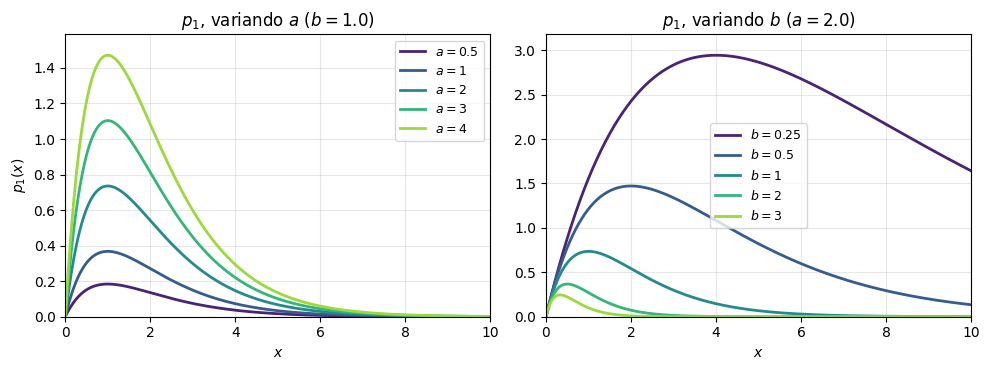

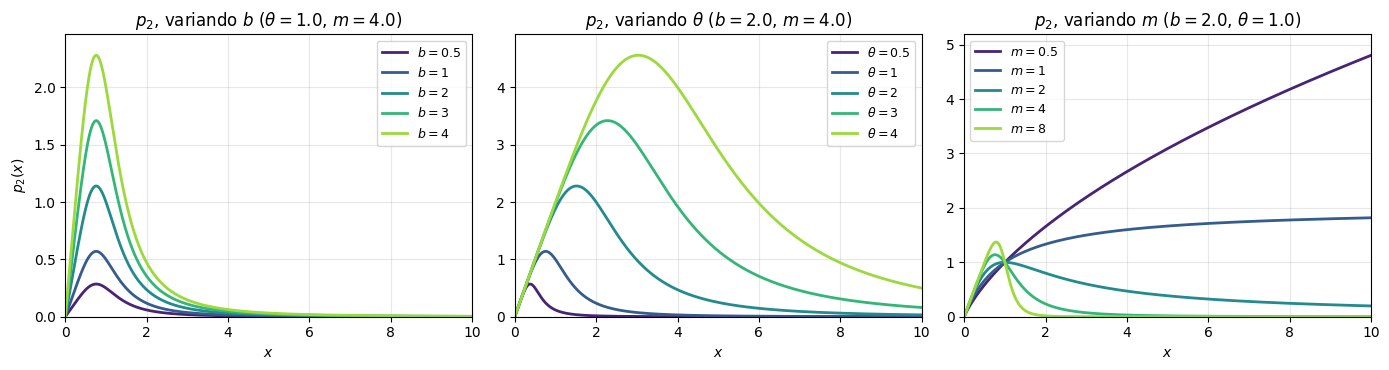

In [32]:
FIGURAS = Path("../../figuras")
FIGURAS.mkdir(exist_ok=True)

# Cálculo: una curva por valor del parámetro, los demás en los valores de referencia
def calcular_familia(f, valores):
    return {v: f(v) for v in valores}

fam_p1_a = calcular_familia(lambda a: p1(x, a, B0), [0.5, 1, 2, 3, 4])
fam_p1_b = calcular_familia(lambda b: p1(x, A0, b), [0.25, 0.5, 1, 2, 3])
fam_p2_b = calcular_familia(lambda b: p2(x, b, T0, M0), [0.5, 1, 2, 3, 4])
fam_p2_t = calcular_familia(lambda t: p2(x, B0_2, t, M0), [0.5, 1, 2, 3, 4])
fam_p2_m = calcular_familia(lambda m: p2(x, B0_2, T0, m), [0.5, 1, 2, 4, 8])

# Gráfica: solo dibuja las curvas ya calculadas
def graficar_familia(ax, curvas, etiqueta, cmap="viridis"):
    colores = plt.get_cmap(cmap)(np.linspace(0.1, 0.85, len(curvas)))
    for (v, y), col in zip(curvas.items(), colores):
        ax.plot(x, y, color=col, lw=2, label=f"${etiqueta}={v:g}$")
    # Cada panel con su propia escala: con ejes compartidos se cortan las curvas
    ymax = max(y.max() for y in curvas.values())
    ax.set_xlim(0, x[-1]); ax.set_ylim(0, 1.08 * ymax)
    ax.set_xlabel("$x$")
    ax.legend(fontsize=9)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
graficar_familia(axs[0], fam_p1_a, "a")
axs[0].set_title(f"$p_1$, variando $a$ ($b={B0}$)"); axs[0].set_ylabel("$p_1(x)$")
graficar_familia(axs[1], fam_p1_b, "b")
axs[1].set_title(f"$p_1$, variando $b$ ($a={A0}$)")
fig.tight_layout()
fig.savefig(FIGURAS / "produccion_p1.pdf")
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
graficar_familia(axs[0], fam_p2_b, "b")
axs[0].set_title(f"$p_2$, variando $b$ ($\\theta={T0}$, $m={M0}$)"); axs[0].set_ylabel("$p_2(x)$")
graficar_familia(axs[1], fam_p2_t, "\\theta")
axs[1].set_title(f"$p_2$, variando $\\theta$ ($b={B0_2}$, $m={M0}$)")
graficar_familia(axs[2], fam_p2_m, "m")
axs[2].set_title(f"$p_2$, variando $m$ ($b={B0_2}$, $\\theta={T0}$)")
fig.tight_layout()
fig.savefig(FIGURAS / "produccion_p2.pdf")
plt.show()

# Inciso 2: comportamiento a largo plazo y $p(x)$ contra $d(x)$

El modelo completo es la iteración $x_{n+1} = f(x_n)$ con

$$f(x) = x - d(x) + p(x), \qquad d(x) = c\,x .$$

**Equilibrios.** La población se queda quieta cuando lo que se destruye es igual a lo que se produce:

$$x^* = f(x^*) \iff p(x^*) = d(x^*) = c\,x^* .$$

Gráficamente, son los cruces de la curva $p(x)$ con la recta $d(x) = c\,x$. Siempre existe $x^*=0$. El equilibrio positivo es:

| | condición para que exista | $x^*$ | $f'(x^*)$ |
|---|---|---|---|
| $p_1$ | $a > c$ | $\dfrac{1}{b}\ln\dfrac{a}{c}$ | $1 - c\,\ln\dfrac{a}{c}$ |
| $p_2$ | $b > c$ | $\theta\left(\dfrac{b}{c}-1\right)^{1/m}$ | $1 - m\,c\left(1-\dfrac{c}{b}\right)$ |

Si no se cumple la condición, la recta $c\,x$ queda siempre por encima de $p(x)$: se destruye más de lo que se produce y $x_n \to 0$.

**Estabilidad.** El equilibrio atrae a las órbitas cercanas si $|f'(x^*)| < 1$:

- $0 < f'(x^*) < 1$: $x_n$ se acerca a $x^*$ sin oscilar.
- $-1 < f'(x^*) < 0$: se acerca oscilando (oscilaciones amortiguadas).
- $f'(x^*) < -1$: el equilibrio se vuelve inestable y aparecen oscilaciones sostenidas (ciclos de periodo 2, 4, …) o caos.

Para $p_2$, el exponente $m$ aparece multiplicando: una médula que se frena muy abruptamente ($m$ grande) desestabiliza la población. Es la idea de Mackey y Glass (1977) sobre enfermedades hematológicas periódicas.

En las gráficas de abajo, el panel izquierdo compara $p(x)$ con $d(x)$ y el derecho muestra la población total $x_n$ con el tiempo.

## Cálculo

Funciones que solo calculan, sin graficar. Las gráficas de abajo nada más llaman a estas funciones y dibujan lo que regresan.

In [33]:
def mapa(p, c):
    # f(x) = x - d(x) + p(x), con d(x) = c x
    return lambda x: x - c * x + p(x)

def iterar(f, x0, N):
    xs = np.empty(N + 1)
    xs[0] = x0
    for n in range(N):
        xs[n + 1] = f(xs[n])
    return xs

def calcular_p_d(p, c, xmax, puntos=800):
    # Valores de la producción p(x) y la destrucción d(x) = c x en [0, xmax]
    xx = np.linspace(0, xmax, puntos)
    return {"x": xx, "p": p(xx), "d": c * xx, "c": c}

def rango_x(serie, xstar):
    # Hasta dónde graficar p y d para que se vean la órbita y el cruce
    return 1.15 * max(serie.max(), 2 * xstar if xstar else 0, 3)

def equilibrio_p1(a, b, c):
    # Regresa (x*, f'(x*)), o (None, None) si no hay equilibrio positivo
    if a <= c:
        return None, None
    return np.log(a / c) / b, 1 - c * np.log(a / c)

def equilibrio_p2(b, theta, m, c):
    if b <= c:
        return None, None
    return theta * (b / c - 1) ** (1 / m), 1 - m * c * (1 - c / b)

def clasificar(xstar, fp):
    if xstar is None:
        return "no hay equilibrio positivo: $x_n \\to 0$"
    if fp > 1:
        tipo = "inestable (se aleja sin oscilar)"
    elif fp >= 0:
        tipo = "estable, sin oscilar"
    elif fp >= -1:
        tipo = "estable, oscilaciones amortiguadas"
    else:
        tipo = "inestable: oscilaciones sostenidas o caos"
    return f"$f'(x^*)={fp:.2f}$: {tipo}"

def calcular_bifurcacion(f_param, valores, x0=0.5, transitorio=1000, guardar=200):
    # Regresa los pares (parámetro, x_n) de los días que se guardan
    x = np.full_like(valores, x0, dtype=float)
    for _ in range(transitorio):
        x = f_param(x, valores)
    X = np.empty((guardar, len(valores)))
    for k in range(guardar):
        x = f_param(x, valores)
        X[k] = x
    return np.tile(valores, guardar), X.ravel()

## Gráficas

`graficar_largo_plazo` solo dibuja: recibe los valores de $p$ y $d$ que calcula `calcular_p_d` y la serie que calcula `iterar`.

In [34]:
def graficar_largo_plazo(curvas, serie, xstar, estado, titulo_p):
    xx, c = curvas["x"], curvas["c"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    # Panel izquierdo: producción contra destrucción
    ax1.plot(xx, curvas["p"], color="C1", lw=2.5, label=f"producción {titulo_p}")
    ax1.plot(xx, curvas["d"], color="C0", lw=2.5, label=f"destrucción $d(x)={c:.2f}\\,x$")
    ax1.fill_between(xx, curvas["p"], curvas["d"], where=curvas["p"] > curvas["d"],
                     color="C2", alpha=0.12, label="$p>d$: la población crece")
    ax1.fill_between(xx, curvas["p"], curvas["d"], where=curvas["p"] < curvas["d"],
                     color="C3", alpha=0.08, label="$p<d$: la población decrece")
    if xstar is not None:
        ax1.plot(xstar, c * xstar, "o", color="k", zorder=5)
        ax1.annotate(f"$x^*={xstar:.2f}$", (xstar, c * xstar),
                     xytext=(8, -16), textcoords="offset points")
    ax1.set_xlim(0, xx[-1]); ax1.set_ylim(bottom=0)
    ax1.set_xlabel("$x$ (glóbulos rojos)")
    ax1.set_ylabel("células por día")
    ax1.set_title("$p(x)$ contra $d(x)$")
    ax1.legend(fontsize=8, loc="upper left")

    # Panel derecho: población total con el tiempo
    ax2.plot(serie, "-o", color="C4", ms=2.5, lw=1)
    if xstar is not None:
        ax2.axhline(xstar, color="k", ls="--", lw=1, label=f"$x^*={xstar:.2f}$")
        ax2.legend(fontsize=9, loc="upper right")
    ax2.set_xlim(0, len(serie) - 1); ax2.set_ylim(bottom=0)
    ax2.set_xlabel("día $n$")
    ax2.set_ylabel("$x_n$")
    ax2.set_title("población total\n" + estado, fontsize=10)

    fig.tight_layout()
    return fig

### Con $p_1(x) = a\,x\,e^{-bx}$

Para ver los distintos regímenes:

- **Extinción:** $a < c$.
- **Equilibrio estable:** valores moderados, por ejemplo $a=2$, $b=1$, $c=0.2$.
- **Oscilaciones:** $c\ln(a/c) > 2$, por ejemplo $c=0.9$ y $a$ arriba de 20.

$b$ solo cambia la escala de $x$: mueve $x^*$ pero no cambia su estabilidad.

In [35]:
def largo_plazo_p1(a=2.0, b=1.0, c=0.2, x0=0.5, N=60):
    p = lambda x: p1(x, a, b)
    xstar, fp = equilibrio_p1(a, b, c)
    serie = iterar(mapa(p, c), x0, N)
    curvas = calcular_p_d(p, c, rango_x(serie, xstar))
    return graficar_largo_plazo(curvas, serie, xstar, clasificar(xstar, fp), "$p_1(x)$")

# continuous_update=False: redibuja solo al soltar el slider.
interactuar(
    largo_plazo_p1,
    a=FloatSlider(value=2.0, min=0.1, max=40.0, step=0.1, description="a", continuous_update=False),
    b=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.05, description="b", continuous_update=False),
    c=FloatSlider(value=0.2, min=0.01, max=1.0, step=0.01, description="c", continuous_update=False),
    x0=FloatSlider(value=0.5, min=0.01, max=10.0, step=0.01, description="x₀", continuous_update=False),
    N=IntSlider(value=60, min=10, max=300, step=10, description="días N", continuous_update=False),
);

### Con $p_2(x) = \dfrac{b\,\theta^m x}{\theta^m + x^m}$

Para ver los distintos regímenes:

- **Extinción:** $b < c$.
- **Equilibrio estable:** $m$ chico, por ejemplo $b=2$, $\theta=1$, $m=2$, $c=0.5$.
- **Oscilaciones:** $m\,c\,(1-c/b) > 2$. Con $b=2$ y $c=0.5$ ocurre a partir de $m \approx 5.3$.

$\theta$ solo cambia la escala de $x$: mueve $x^*$ pero no cambia su estabilidad.

In [36]:
def largo_plazo_p2(b=2.0, theta=1.0, m=2.0, c=0.5, x0=0.5, N=60):
    p = lambda x: p2(x, b, theta, m)
    xstar, fp = equilibrio_p2(b, theta, m, c)
    serie = iterar(mapa(p, c), x0, N)
    curvas = calcular_p_d(p, c, rango_x(serie, xstar))
    return graficar_largo_plazo(curvas, serie, xstar, clasificar(xstar, fp), "$p_2(x)$")

# continuous_update=False: redibuja solo al soltar el slider.
interactuar(
    largo_plazo_p2,
    b=FloatSlider(value=2.0, min=0.1, max=5.0, step=0.1, description="b", continuous_update=False),
    theta=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.05, description="θ", continuous_update=False),
    m=FloatSlider(value=2.0, min=0.2, max=20.0, step=0.1, description="m", continuous_update=False),
    c=FloatSlider(value=0.5, min=0.01, max=1.0, step=0.01, description="c", continuous_update=False),
    x0=FloatSlider(value=0.5, min=0.01, max=10.0, step=0.01, description="x₀", continuous_update=False),
    N=IntSlider(value=60, min=10, max=300, step=10, description="días N", continuous_update=False),
);

### Figuras para el reporte: familias de curvas

Igual que en el inciso 1: en cada panel cambia un solo parámetro y los demás quedan en los valores de referencia,
con $c = 0.5$ fijo. Para cada función hay dos figuras:

1. **$p$ contra $d$:** una curva de producción por valor del parámetro y la recta de destrucción $d(x) = c\,x$
   (negra, punteada). Cada punto marca el equilibrio $x^*$, donde $p$ cruza a $d$.
   El eje vertical se recorta para que se vea la zona del cruce, así que los picos más altos pueden quedar fuera.
2. **Población $x_n$:** la serie de días desde $x_0 = 0.5$ con los mismos valores y colores.

Los valores se eligieron para que aparezcan todos los regímenes:

| | valores | qué pasa |
|---|---|---|
| $p_1$, $a$ ($b=1$) | 0.4, 1, 3, 10, 40 | $a<c$: extinción; 1 y 3: equilibrio sin oscilar; 10: oscilaciones amortiguadas; 40: oscilación sostenida ($f'(x^*)=-1.19$) |
| $p_1$, $b$ ($a=2$) | 0.5, 1, 2, 4 | solo cambia la escala: $x^* = \ln(a/c)/b$, misma $f'(x^*)$ |
| $p_2$, $b$ ($\theta=1$, $m=4$) | 0.4, 1, 2, 4, 8 | $b<c$: extinción; los demás estables, oscilan más conforme $b$ crece |
| $p_2$, $\theta$ ($b=2$, $m=4$) | 0.5, 1, 2, 4 | solo cambia la escala: $x^* = \theta\,(b/c-1)^{1/m}$, misma $f'(x^*)$ |
| $p_2$, $m$ ($b=2$, $\theta=1$) | 1, 2, 4, 6, 10 | 1 y 2: sin oscilar; 4: amortiguadas; 6: oscilación sostenida; 10: caos |

In [37]:
# Cálculo: para cada valor del parámetro, las curvas p y d, el equilibrio y la serie x_n
C_FAM, X0_FAM, N_FAM = 0.5, 0.5, 40

def calcular_familia_largo_plazo(p_de, equilibrio_de, valores, c=C_FAM, x0=X0_FAM, N=N_FAM):
    # p_de(v) regresa la función p con el parámetro v; equilibrio_de(v) regresa (x*, f'(x*))
    familia = {}
    for v in valores:
        p = p_de(v)
        xstar, fp = equilibrio_de(v)
        familia[v] = {"p": p, "xstar": xstar, "fp": fp,
                      "serie": iterar(mapa(p, c), x0, N)}
    # Mismo rango de x para todo el panel: que se vean todos los cruces
    xs = [f["xstar"] for f in familia.values() if f["xstar"] is not None]
    xmax = max(1.6 * max(xs, default=0), 3)
    xx = np.linspace(0, xmax, 800)
    for f in familia.values():
        f["x"], f["y"] = xx, f["p"](xx)
    return {"curvas": familia, "x": xx, "d": c * xx, "c": c}

fam_lp_p1_a = calcular_familia_largo_plazo(lambda a: (lambda x: p1(x, a, B0)),
                                           lambda a: equilibrio_p1(a, B0, C_FAM), [0.4, 1, 3, 10, 40])
fam_lp_p1_b = calcular_familia_largo_plazo(lambda b: (lambda x: p1(x, A0, b)),
                                           lambda b: equilibrio_p1(A0, b, C_FAM), [0.5, 1, 2, 4])
fam_lp_p2_b = calcular_familia_largo_plazo(lambda b: (lambda x: p2(x, b, T0, M0)),
                                           lambda b: equilibrio_p2(b, T0, M0, C_FAM), [0.4, 1, 2, 4, 8])
fam_lp_p2_t = calcular_familia_largo_plazo(lambda t: (lambda x: p2(x, B0_2, t, M0)),
                                           lambda t: equilibrio_p2(B0_2, t, M0, C_FAM), [0.5, 1, 2, 4])
fam_lp_p2_m = calcular_familia_largo_plazo(lambda m: (lambda x: p2(x, B0_2, T0, m)),
                                           lambda m: equilibrio_p2(B0_2, T0, m, C_FAM), [1, 2, 4, 6, 10])

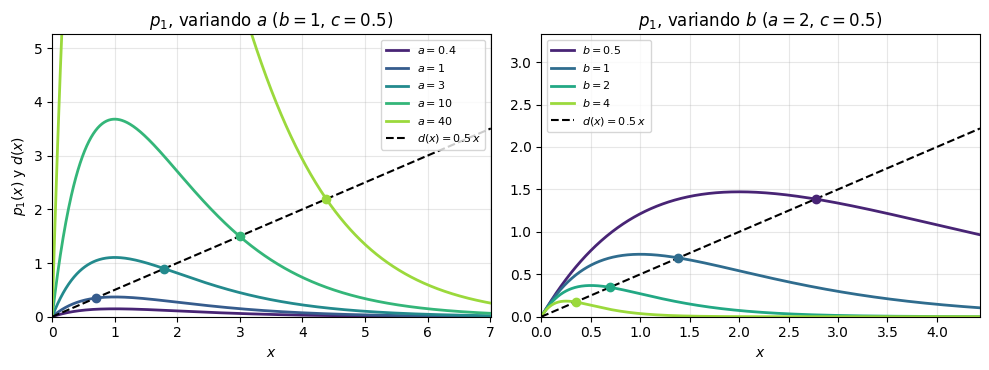

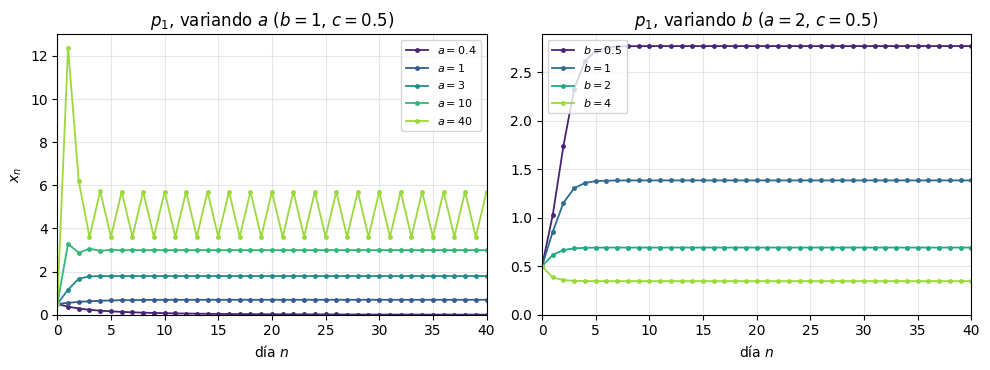

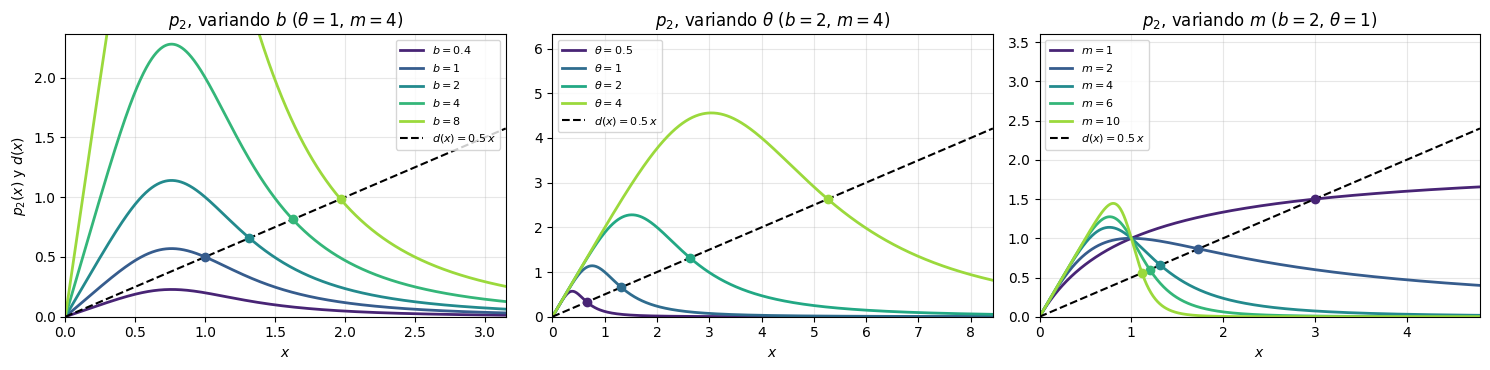

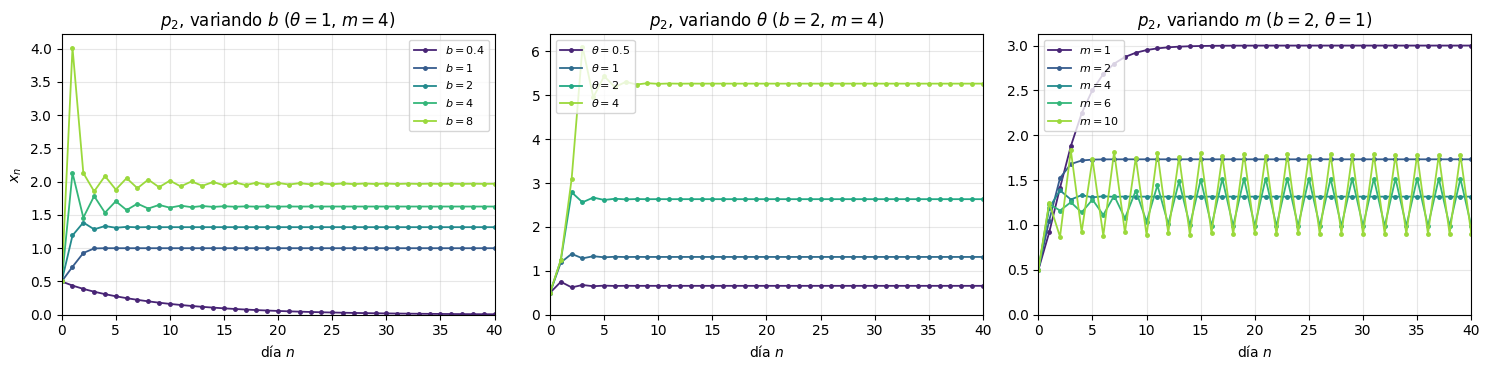

In [38]:
# Gráfica: solo dibuja lo que regresa calcular_familia_largo_plazo
def colores_de(familia, cmap="viridis"):
    return plt.get_cmap(cmap)(np.linspace(0.1, 0.85, len(familia["curvas"])))

def graficar_p_d_familia(ax, familia, etiqueta):
    for (v, f), col in zip(familia["curvas"].items(), colores_de(familia)):
        ax.plot(f["x"], f["y"], color=col, lw=2, label=f"${etiqueta}={v:g}$")
        if f["xstar"] is not None:
            ax.plot(f["xstar"], familia["c"] * f["xstar"], "o", color=col, ms=6, zorder=5)
    ax.plot(familia["x"], familia["d"], "k--", lw=1.5, label=f"$d(x)={familia['c']:g}\\,x$")
    # Recortar a la zona del cruce: hasta un poco arriba de la recta d al final
    ax.set_xlim(0, familia["x"][-1])
    ax.set_ylim(0, 1.5 * familia["d"][-1])
    ax.set_xlabel("$x$")
    ax.legend(fontsize=8)

def graficar_poblacion_familia(ax, familia, etiqueta):
    for (v, f), col in zip(familia["curvas"].items(), colores_de(familia)):
        ax.plot(f["serie"], "o-", color=col, lw=1.3, ms=2.5, label=f"${etiqueta}={v:g}$")
    ax.set_xlim(0, N_FAM)
    ax.set_ylim(0, None)
    ax.set_xlabel("día $n$")
    ax.legend(fontsize=8)

def figura_familias(graficar, paneles, ylabel, archivo):
    fig, axs = plt.subplots(1, len(paneles), figsize=(5 * len(paneles), 3.8))
    for ax, (familia, etiqueta, titulo) in zip(axs, paneles):
        graficar(ax, familia, etiqueta)
        ax.set_title(titulo)
    axs[0].set_ylabel(ylabel)
    fig.tight_layout()
    fig.savefig(FIGURAS / archivo)
    plt.show()

paneles_p1 = [(fam_lp_p1_a, "a", f"$p_1$, variando $a$ ($b={B0:g}$, $c={C_FAM:g}$)"),
              (fam_lp_p1_b, "b", f"$p_1$, variando $b$ ($a={A0:g}$, $c={C_FAM:g}$)")]
paneles_p2 = [(fam_lp_p2_b, "b", f"$p_2$, variando $b$ ($\\theta={T0:g}$, $m={M0:g}$)"),
              (fam_lp_p2_t, "\\theta", f"$p_2$, variando $\\theta$ ($b={B0_2:g}$, $m={M0:g}$)"),
              (fam_lp_p2_m, "m", f"$p_2$, variando $m$ ($b={B0_2:g}$, $\\theta={T0:g}$)")]

figura_familias(graficar_p_d_familia, paneles_p1, "$p_1(x)$ y $d(x)$", "largo_plazo_p1_pd.pdf")
figura_familias(graficar_poblacion_familia, paneles_p1, "$x_n$", "largo_plazo_p1_poblacion.pdf")
figura_familias(graficar_p_d_familia, paneles_p2, "$p_2(x)$ y $d(x)$", "largo_plazo_p2_pd.pdf")
figura_familias(graficar_poblacion_familia, paneles_p2, "$x_n$", "largo_plazo_p2_poblacion.pdf")

### Figura para el reporte: diagramas de bifurcación

Resumen del largo plazo en una sola imagen. Para cada valor del parámetro se itera el modelo 1000 días para descartar el transitorio, y se grafican los 200 días siguientes.

- Un solo punto por valor del parámetro significa que la población se estabiliza en un equilibrio.
- Dos puntos significan un ciclo de periodo 2.
- Una nube de puntos significa caos.

La línea punteada marca el valor del parámetro donde $f'(x^*) = -1$, según la tabla de arriba. Primero se calculan los datos y después se grafican.

In [39]:
# Cálculo
c_b, b_b = 0.5, 1.0     # p1: b y c fijos, variando a
b2_b, t_b = 2.0, 1.0    # p2: b y theta fijos, variando m

a_vals = np.linspace(0.1, 150, 3000)
bif_p1 = calcular_bifurcacion(lambda x, a: mapa(lambda y: p1(y, a, b_b), c_b)(x), a_vals)
a_critico = c_b * np.exp(2 / c_b)                 # c ln(a/c) = 2

m_vals = np.linspace(0.5, 20, 3000)
bif_p2 = calcular_bifurcacion(lambda x, m: mapa(lambda y: p2(y, b2_b, t_b, m), c_b)(x), m_vals)
m_critico = 2 / (c_b * (1 - c_b / b2_b))         # m c (1 - c/b) = 2

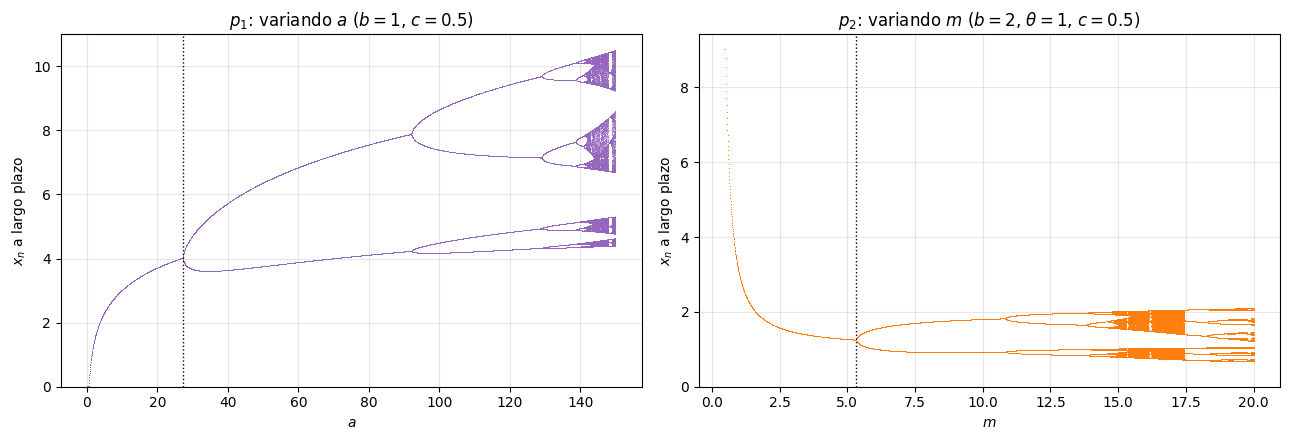

In [40]:
# Gráfica
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

axs[0].plot(*bif_p1, ",", color="C4", alpha=0.5)
axs[0].axvline(a_critico, color="k", ls=":", lw=1)
axs[0].set_xlabel("$a$")
axs[0].set_title(f"$p_1$: variando $a$ ($b={b_b:g}$, $c={c_b:g}$)")

axs[1].plot(*bif_p2, ",", color="C1", alpha=0.5)
axs[1].axvline(m_critico, color="k", ls=":", lw=1)
axs[1].set_xlabel("$m$")
axs[1].set_title(f"$p_2$: variando $m$ ($b={b2_b:g}$, $\\theta={t_b:g}$, $c={c_b:g}$)")

for ax in axs:
    ax.set_ylabel("$x_n$ a largo plazo")
    ax.set_ylim(bottom=0)
fig.tight_layout()
fig.savefig(FIGURAS / "largo_plazo_bifurcacion.pdf")
plt.show()